# Lab Task 04 - Geometric Transformations with Custom Inputs

**Name:** Qurat ul Ain Fatima

**Roll No:** 2024-SE-05

## 1. Import Libraries

In [1]:
import os
import math
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Set figure size and remove extra white space
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["savefig.pad_inches"] = 0

# Create folder to save transformed images
os.makedirs("saved_images", exist_ok=True)

## 2. Load the image and check it

In [3]:
path = "input.png"

# Check that the file exists
if not os.path.exists(path):
    raise FileNotFoundError("Image file not found: " + path)

# Read the image
image = cv2.imread(path)

if image is None:
    raise ValueError("Image could not be decoded")

# Convert BGR to RGB
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Check image dimensions
if image.shape[0] == 0 or image.shape[1] == 0:
    raise ValueError("Image has zero size")

# Keep original image unchanged
original = image.copy()

print("Image loaded successfully!")
print("Width:", original.shape[1])
print("Height:", original.shape[0])
print("Array Shape:", original.shape)

Image loaded successfully!
Width: 400
Height: 225
Array Shape: (225, 400, 3)


## 3. Helper functions

In [4]:
def show_image(img, title, file_name=None):
    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

    if file_name is not None:
        plt.savefig("saved_images/" + file_name,
                    bbox_inches="tight", pad_inches=0)

    plt.show()


def print_properties(img, operation=None, params=None):

    if operation is not None:
        print("Operation  :", operation)

    if params is not None:
        print("Parameters :", params)

    print("Width      :", img.shape[1])
    print("Height     :", img.shape[0])
    print("Array shape:", img.shape)

## 4. Original image

Width      : 400
Height     : 225
Array shape: (225, 400, 3)


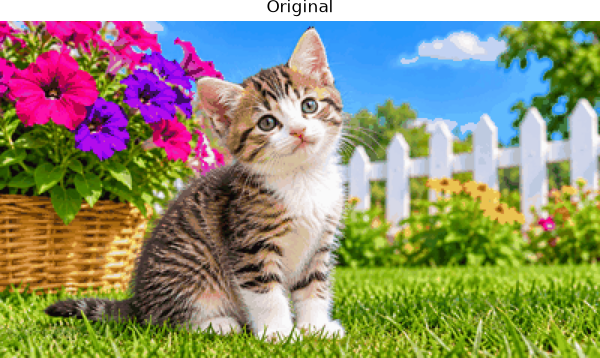

In [5]:
print_properties(original)

show_image(original, "Original", "original.png")

## 5. Create Reusable Transform Function

In [6]:
def transform(img, operation, **params):

    if img is None or img.size == 0:
        raise ValueError("Invalid input image")

    max_pixels = 100_000_000

    interpolation_methods = {
        "nearest": cv2.INTER_NEAREST,
        "bilinear": cv2.INTER_LINEAR,
        "bicubic": cv2.INTER_CUBIC,
        "lanczos": cv2.INTER_LANCZOS4
    }

    def get_number(value, name):
        try:
            value = float(value)
        except (TypeError, ValueError):
            raise ValueError(f"{name} must be numeric")

        if not math.isfinite(value):
            raise ValueError(f"{name} must be finite")

        return value

    h, w = img.shape[:2]

    if operation == "scaling":

        sx = get_number(params.get("sx"), "sx")
        sy = get_number(params.get("sy"), "sy")

        if sx <= 0 or sy <= 0:
            raise ValueError("Scale factors must be greater than zero")

        method = params.get("interpolation")

        if method not in interpolation_methods:
            raise ValueError("Unsupported interpolation method")

        new_w = int(round(w * sx))
        new_h = int(round(h * sy))

        if new_w < 1 or new_h < 1:
            raise ValueError("Invalid output dimensions")

        if new_w * new_h > max_pixels:
            raise ValueError("Output image is too large")

        result = cv2.resize(
            img,
            (new_w, new_h),
            interpolation=interpolation_methods[method]
        )

    elif operation == "cropping":

        left = params.get("left")
        top = params.get("top")
        right = params.get("right")
        bottom = params.get("bottom")

        coordinates = [left, top, right, bottom]

        if any(type(v) not in (int, np.int32, np.int64) for v in coordinates):
            raise ValueError("Crop coordinates must be integers")

        if not (0 <= left < right <= w):
            raise ValueError("Invalid horizontal crop coordinates")

        if not (0 <= top < bottom <= h):
            raise ValueError("Invalid vertical crop coordinates")

        result = img[top:bottom, left:right].copy()

    elif operation == "flipping":

        direction = params.get("direction")

        flip_codes = {
            "horizontal": 1,
            "vertical": 0,
            "both": -1
        }

        if direction not in flip_codes:
            raise ValueError("Invalid flipping direction")

        result = cv2.flip(img, flip_codes[direction])

    elif operation == "translation":

        tx = get_number(params.get("tx"), "tx")
        ty = get_number(params.get("ty"), "ty")

        matrix = np.float32([
            [1, 0, tx],
            [0, 1, ty]
        ])

        result = cv2.warpAffine(
            img, matrix, (w, h)
        )

    elif operation == "rotation":

        angle = get_number(params.get("angle"), "angle")
        expand = params.get("expand")

        if type(expand) is not bool:
            raise ValueError("Expand must be True or False")

        center = (w / 2, h / 2)

        matrix = cv2.getRotationMatrix2D(
            center, angle, 1.0
        )

        if expand:
            cos = abs(matrix[0, 0])
            sin = abs(matrix[0, 1])

            new_w = int(h * sin + w * cos)
            new_h = int(h * cos + w * sin)

            matrix[0, 2] += (new_w - w) / 2
            matrix[1, 2] += (new_h - h) / 2
        else:
            new_w, new_h = w, h

        if new_w < 1 or new_h < 1:
            raise ValueError("Invalid rotation dimensions")

        if new_w * new_h > max_pixels:
            raise ValueError("Output image is too large")

        result = cv2.warpAffine(
            img, matrix, (new_w, new_h)
        )

    else:
        raise ValueError("Unknown transformation operation")

    if result.size == 0:
        raise ValueError("Transformation produced an empty image")

    return result

## 6. Demonstrations with Custom Values

In [8]:
def demo(title, operation, file_name, **params):

    result = transform(original, operation, **params)

    print_properties(result, operation, params)

    show_image(result, title, file_name)

    return result

### Scaling (Reduction, Enlargement, Non-proportional)

Operation  : scaling
Parameters : {'sx': 0.4, 'sy': 0.4, 'interpolation': 'bilinear'}
Width      : 160
Height     : 90
Array shape: (90, 160, 3)


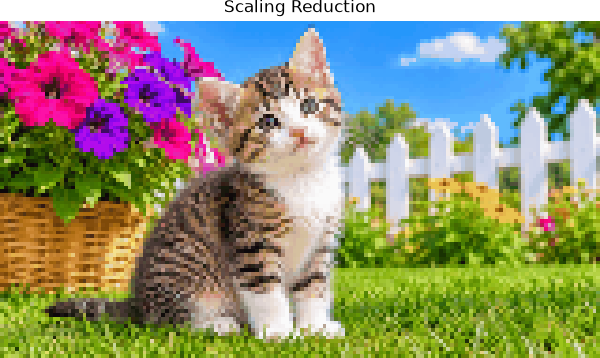

array([[[248,   3, 158],
        [240,  15, 144],
        [220, 193, 181],
        ...,
        [ 88, 122,   5],
        [ 91, 121,   5],
        [ 74, 117,   1]],

       [[168,   6,  93],
        [179,   6, 104],
        [235, 125, 187],
        ...,
        [ 68, 112,   1],
        [ 68, 103,   2],
        [ 68, 101,   2]],

       [[248,   2, 167],
        [250,  10, 166],
        [213,   5,  95],
        ...,
        [ 41,  80,   2],
        [ 41,  80,   2],
        [ 66,  81,   3]],

       ...,

       [[151, 181,  58],
        [200, 219, 109],
        [114, 157,   9],
        ...,
        [135, 177,  15],
        [151, 192,  23],
        [161, 191,  61]],

       [[111, 144,  17],
        [129, 165,  28],
        [166, 200,  56],
        ...,
        [151, 190,  23],
        [111, 158,   9],
        [155, 188,  31]],

       [[ 93, 136,   3],
        [175, 202,  52],
        [190, 217,  81],
        ...,
        [145, 184,  21],
        [128, 172,  12],
        [126, 169,  11]]

In [9]:
demo(
    "Scaling Reduction",
    "scaling",
    "scale_reduce.png",
    sx=0.4,
    sy=0.4,
    interpolation="bilinear"
)

### Scaling Enlargement

Operation  : scaling
Parameters : {'sx': 1.5, 'sy': 1.5, 'interpolation': 'bilinear'}
Width      : 600
Height     : 338
Array shape: (338, 600, 3)


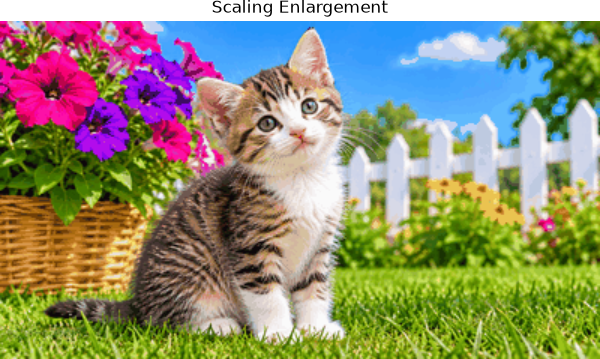

array([[[248,   2, 167],
        [248,   2, 167],
        [248,   2, 167],
        ...,
        [ 91, 122,   2],
        [ 91, 122,   2],
        [ 91, 122,   2]],

       [[247,   4, 144],
        [248,   3, 155],
        [248,   2, 167],
        ...,
        [ 79, 118,   1],
        [ 79, 118,   1],
        [ 79, 118,   1]],

       [[237,   6, 113],
        [237,   4, 133],
        [238,   2, 152],
        ...,
        [ 68, 113,   1],
        [ 68, 113,   1],
        [ 68, 113,   1]],

       ...,

       [[ 73, 126,   1],
        [ 80, 128,   1],
        [ 94, 134,   8],
        ...,
        [126, 169,  11],
        [127, 170,  11],
        [127, 171,  11]],

       [[ 85, 134,   1],
        [ 94, 139,   3],
        [109, 149,  14],
        ...,
        [127, 170,  11],
        [126, 169,  11],
        [126, 169,  11]],

       [[ 97, 143,   1],
        [105, 149,   6],
        [120, 161,  19],
        ...,
        [127, 170,  11],
        [126, 169,  11],
        [126, 169,  11]]

In [10]:
demo(
    "Scaling Enlargement",
    "scaling",
    "scale_enlarge.png",
    sx=1.5,
    sy=1.5,
    interpolation="bilinear"
)

### Non-Proportional Scaling

Operation  : scaling
Parameters : {'sx': 1.5, 'sy': 0.8, 'interpolation': 'bilinear'}
Width      : 600
Height     : 180
Array shape: (180, 600, 3)


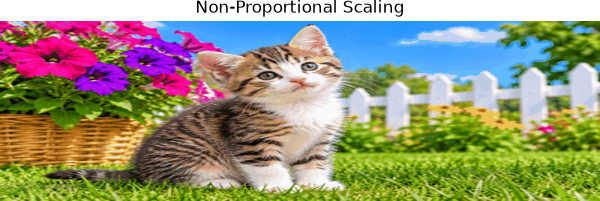

array([[[248,   3, 161],
        [248,   2, 164],
        [248,   2, 167],
        ...,
        [ 88, 121,   2],
        [ 88, 121,   2],
        [ 88, 121,   2]],

       [[224,   5, 104],
        [225,   4, 118],
        [225,   3, 132],
        ...,
        [ 68, 111,   1],
        [ 68, 111,   1],
        [ 68, 111,   1]],

       [[187,   4,  75],
        [168,   5,  78],
        [149,   5,  82],
        ...,
        [ 68, 103,   1],
        [ 68, 104,   1],
        [ 68, 104,   1]],

       ...,

       [[ 99, 145,   7],
        [ 90, 132,   4],
        [ 84, 121,   2],
        ...,
        [128, 172,  13],
        [147, 183,  24],
        [162, 190,  34]],

       [[ 73, 126,   1],
        [ 78, 126,   1],
        [ 89, 131,   6],
        ...,
        [125, 168,  11],
        [128, 171,  12],
        [129, 173,  12]],

       [[ 94, 141,   1],
        [103, 147,   5],
        [118, 158,  17],
        ...,
        [127, 170,  11],
        [126, 169,  11],
        [126, 169,  11]]

In [11]:
demo(
    "Non-Proportional Scaling",
    "scaling",
    "scale_non_proportional.png",
    sx=1.5,
    sy=0.8,
    interpolation="bilinear"
)

### Cropping Transformation

Operation  : cropping
Parameters : {'left': 40, 'top': 22, 'right': 320, 'bottom': 180}
Width      : 280
Height     : 158
Array shape: (158, 280, 3)


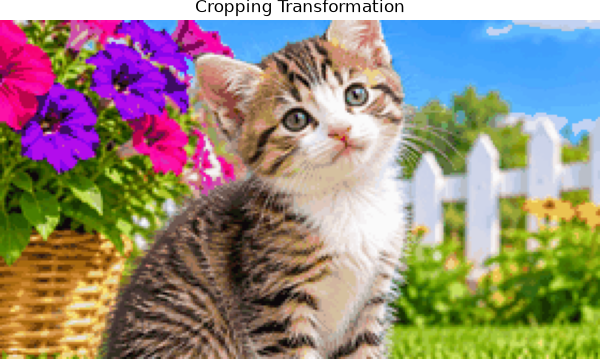

In [12]:
h, w = original.shape[:2]

left = int(w * 0.1)
top = int(h * 0.1)
right = int(w * 0.8)
bottom = int(h * 0.8)

cropped_image = demo(
    "Cropping Transformation",
    "cropping",
    "cropped_image.png",
    left=left,
    top=top,
    right=right,
    bottom=bottom
)

### Flipping Transformation

Operation  : flipping
Parameters : {'direction': 'horizontal'}
Width      : 400
Height     : 225
Array shape: (225, 400, 3)


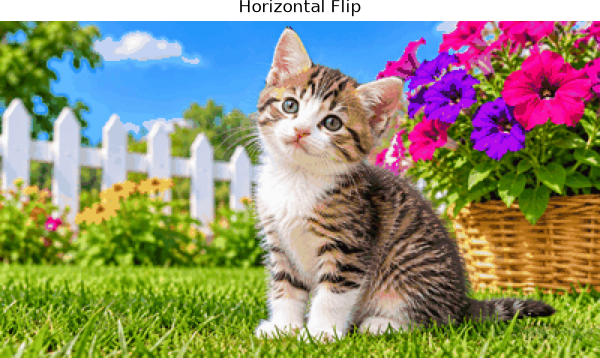

In [13]:
horizontal_flip = demo(
    "Horizontal Flip",
    "flipping",
    "horizontal_flip.png",
    direction="horizontal"
)

Operation  : flipping
Parameters : {'direction': 'vertical'}
Width      : 400
Height     : 225
Array shape: (225, 400, 3)


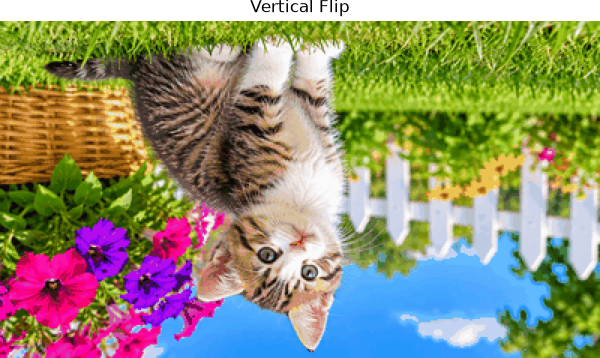

In [14]:
vertical_flip = demo(
    "Vertical Flip",
    "flipping",
    "vertical_flip.png",
    direction="vertical"
)

Operation  : flipping
Parameters : {'direction': 'both'}
Width      : 400
Height     : 225
Array shape: (225, 400, 3)


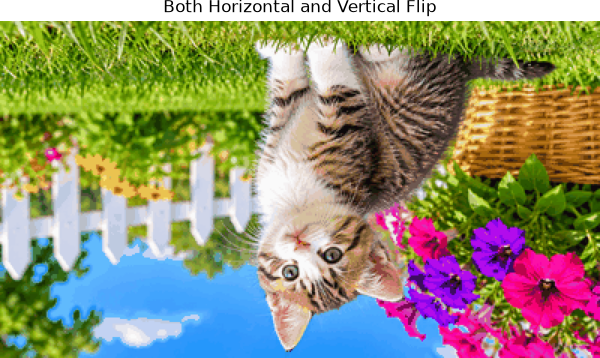

In [15]:
both_flip = demo(
    "Both Horizontal and Vertical Flip",
    "flipping",
    "both_flip.png",
    direction="both"
)

### Translation Transformation

Operation  : translation
Parameters : {'tx': 100, 'ty': 50}
Width      : 400
Height     : 225
Array shape: (225, 400, 3)


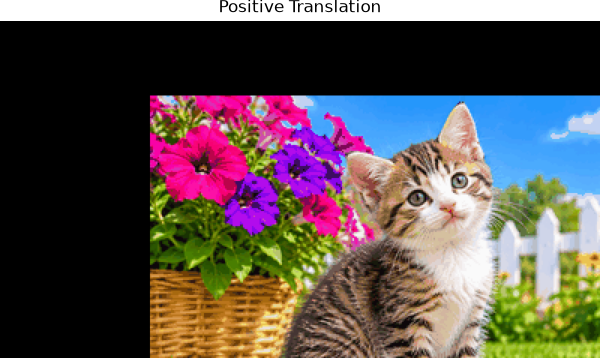

In [16]:
translated_positive = demo(
    "Positive Translation",
    "translation",
    "translation_positive.png",
    tx=100,
    ty=50
)

### Negative Translation

Operation  : translation
Parameters : {'tx': -100, 'ty': -50}
Width      : 400
Height     : 225
Array shape: (225, 400, 3)


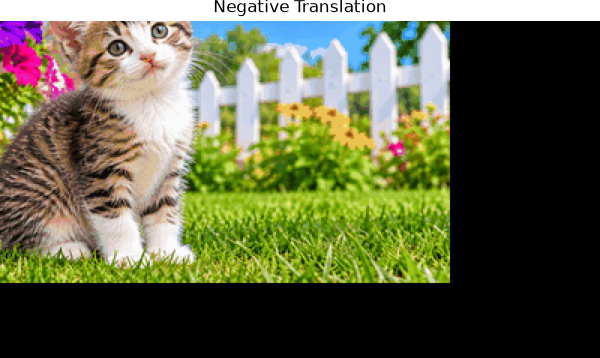

In [17]:
translated_negative = demo(
    "Negative Translation",
    "translation",
    "translation_negative.png",
    tx=-100,
    ty=-50
)

### Rotation Transformation - Positive Angle

Operation  : rotation
Parameters : {'angle': 45, 'expand': False}
Width      : 400
Height     : 225
Array shape: (225, 400, 3)


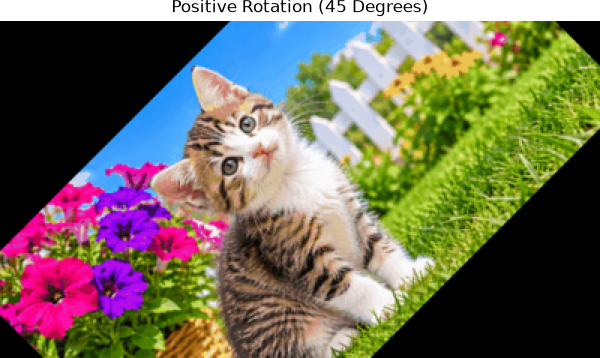

In [18]:
rotated_positive = demo(
    "Positive Rotation (45 Degrees)",
    "rotation",
    "rotation_positive.png",
    angle=45,
    expand=False
)

### Rotation Transformation - Negative Angle

Operation  : rotation
Parameters : {'angle': -45, 'expand': False}
Width      : 400
Height     : 225
Array shape: (225, 400, 3)


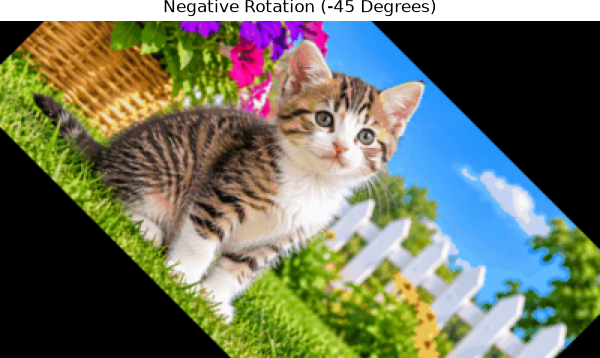

In [19]:
rotated_negative = demo(
    "Negative Rotation (-45 Degrees)",
    "rotation",
    "rotation_negative.png",
    angle=-45,
    expand=False
)

### Rotation with Canvas Expansion

Operation  : rotation
Parameters : {'angle': 45, 'expand': True}
Width      : 441
Height     : 441
Array shape: (441, 441, 3)


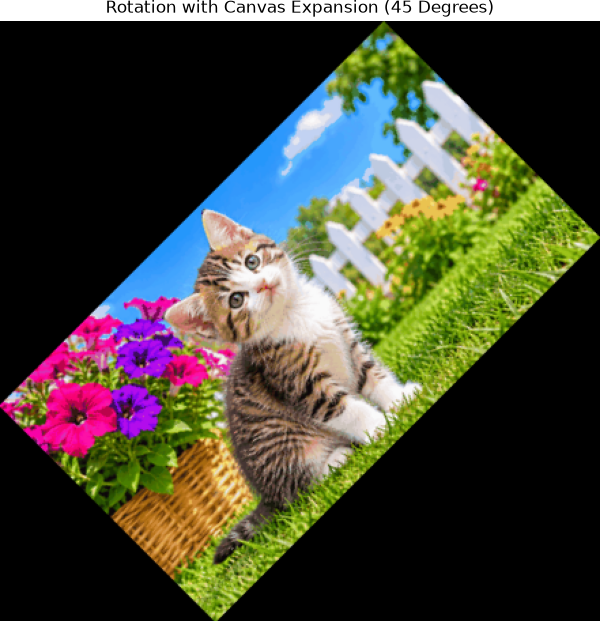

In [20]:
rotated_expanded = demo(
    "Rotation with Canvas Expansion (45 Degrees)",
    "rotation",
    "rotation_expanded.png",
    angle=45,
    expand=True
)

## 7. Interpolation Comparison

In [21]:
h, w = original.shape[:2]

# Extract a small patch from original image
patch = original[
    int(h * 0.25):int(h * 0.50),
    int(w * 0.25):int(w * 0.50)
]

print("Original Patch Shape:", patch.shape)

Original Patch Shape: (56, 100, 3)


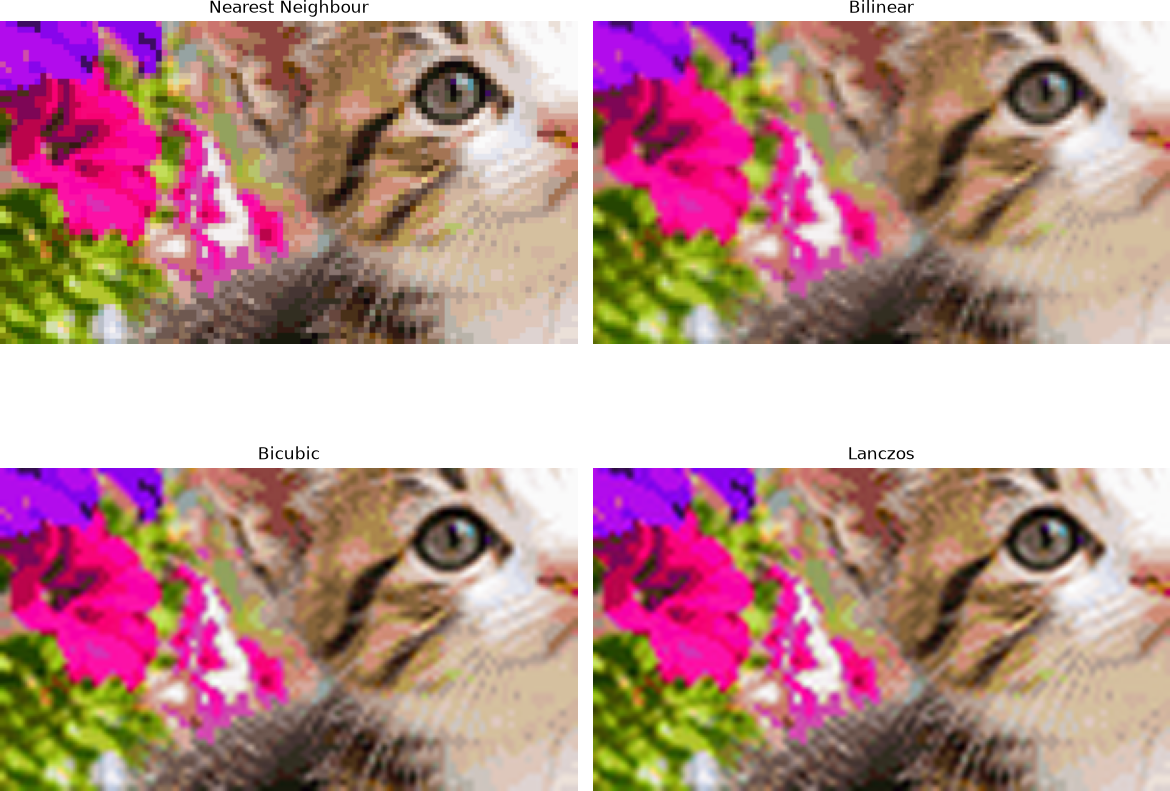

In [22]:
methods = {
    "Nearest Neighbour": cv2.INTER_NEAREST,
    "Bilinear": cv2.INTER_LINEAR,
    "Bicubic": cv2.INTER_CUBIC,
    "Lanczos": cv2.INTER_LANCZOS4
}

plt.figure(figsize=(12, 10))

for i, (name, method) in enumerate(methods.items()):

    enlarged = cv2.resize(
        patch,
        None,
        fx=3,
        fy=3,
        interpolation=method
    )

    plt.subplot(2, 2, i + 1)
    plt.imshow(enlarged)
    plt.title(name)
    plt.axis("off")

    cv2.imwrite(
        "saved_images/" + name.replace(" ", "_") + ".png",
        cv2.cvtColor(enlarged, cv2.COLOR_RGB2BGR)
    )

plt.tight_layout()
plt.show()

### Interpolation Observations

- Nearest Neighbour: Produces sharp but pixelated images.
- Bilinear: Produces smoother images.
- Bicubic: Produces better smoothness and details.
- Lanczos: Produces high-quality results with better detail preservation.

## 8. Input Validation and Error Handling

### Testing Invalid Inputs

In [23]:
invalid_tests = [
    ("Scaling", "scaling",
     {"sx": -1, "sy": 1, "interpolation": "bilinear"}),

    ("Cropping", "cropping",
     {"left": 100, "top": 100, "right": 50, "bottom": 50}),

    ("Flipping", "flipping",
     {"direction": "diagonal"}),

    ("Translation", "translation",
     {"tx": float("nan"), "ty": 50}),

    ("Rotation", "rotation",
     {"angle": "abc", "expand": False})
]

for name, operation, params in invalid_tests:

    print("\nTesting:", name)

    try:
        transform(original, operation, **params)
        print("Test Failed: Invalid input was accepted")

    except (ValueError, TypeError) as e:
        print("Test Passed:", e)


Testing: Scaling
Test Passed: Scale factors must be greater than zero

Testing: Cropping
Test Passed: Invalid horizontal crop coordinates

Testing: Flipping
Test Passed: Invalid flipping direction

Testing: Translation
Test Passed: tx must be finite

Testing: Rotation
Test Passed: angle must be numeric


## 9. Identity Transformation Tests

In [24]:
identity_tests = [
    (
        "Scaling (1, 1)",
        transform(original, "scaling",
                  sx=1, sy=1,
                  interpolation="nearest")
    ),

    (
        "Translation (0, 0)",
        transform(original, "translation",
                  tx=0, ty=0)
    ),

    (
        "Rotation (0 Degrees)",
        transform(original, "rotation",
                  angle=0, expand=False)
    )
]

for name, result in identity_tests:

    passed = np.array_equal(original, result)

    print("Test:", name)
    print("Expected: Original image unchanged")
    print("Actual:", "Unchanged" if passed else "Changed")
    print("Result:", "PASS" if passed else "FAIL")
    print("-" * 40)

Test: Scaling (1, 1)
Expected: Original image unchanged
Actual: Unchanged
Result: PASS
----------------------------------------
Test: Translation (0, 0)
Expected: Original image unchanged
Actual: Unchanged
Result: PASS
----------------------------------------
Test: Rotation (0 Degrees)
Expected: Original image unchanged
Actual: Unchanged
Result: PASS
----------------------------------------


### Identity Transformation Observations

- Scaling with factors 1 and 1 keeps the original image unchanged.
- Translation with offsets 0 and 0 does not move the image.
- Rotation with angle 0 does not rotate the image.

All three identity tests should pass.

## 10. User Input and Operation Selection

Available Transformations:
1. Scaling
2. Cropping
3. Flipping
4. Translation
5. Rotation


Select operation (1-5):  1
Enter horizontal scale factor:  1.5
Enter vertical scale factor:  1.5
Enter interpolation (nearest/bilinear/bicubic/lanczos):  bilinear



Transformation Successful!
Operation  : Scaling
Width      : 600
Height     : 338
Array shape: (338, 600, 3)


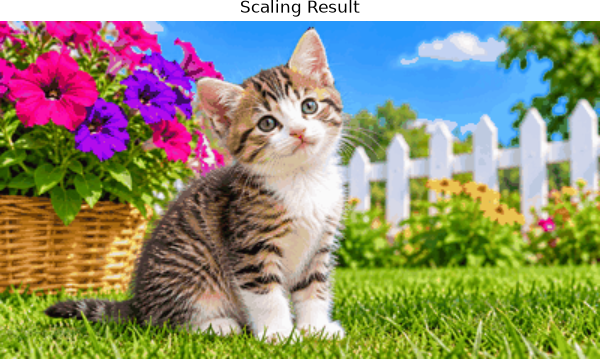

In [25]:
while True:

    try:
        print("Available Transformations:")
        print("1. Scaling")
        print("2. Cropping")
        print("3. Flipping")
        print("4. Translation")
        print("5. Rotation")

        choice = input("Select operation (1-5): ")

        if choice == "1":
            sx = float(input("Enter horizontal scale factor: "))
            sy = float(input("Enter vertical scale factor: "))
            method = input("Enter interpolation (nearest/bilinear/bicubic/lanczos): ")

            result = transform(
                original, "scaling",
                sx=sx, sy=sy,
                interpolation=method
            )

            operation = "Scaling"

        elif choice == "2":
            left = int(input("Enter left coordinate: "))
            top = int(input("Enter top coordinate: "))
            right = int(input("Enter right coordinate: "))
            bottom = int(input("Enter bottom coordinate: "))

            result = transform(
                original, "cropping",
                left=left, top=top,
                right=right, bottom=bottom
            )

            operation = "Cropping"

        elif choice == "3":
            direction = input(
                "Enter direction (horizontal/vertical/both): "
            )

            result = transform(
                original, "flipping",
                direction=direction
            )

            operation = "Flipping"

        elif choice == "4":
            tx = float(input("Enter horizontal offset: "))
            ty = float(input("Enter vertical offset: "))

            result = transform(
                original, "translation",
                tx=tx, ty=ty
            )

            operation = "Translation"

        elif choice == "5":
            angle = float(input("Enter rotation angle: "))
            expand_input = input("Expand canvas? (yes/no): ").lower()

            if expand_input not in ["yes", "no"]:
                raise ValueError("Enter yes or no")

            result = transform(
                original, "rotation",
                angle=angle,
                expand=(expand_input == "yes")
            )

            operation = "Rotation"

        else:
            raise ValueError("Invalid operation selection")

        print("\nTransformation Successful!")

        print_properties(result, operation)

        show_image(result, operation + " Result")

        cv2.imwrite(
            "saved_images/user_result.png",
            cv2.cvtColor(result, cv2.COLOR_RGB2BGR)
        )

        break

    except (ValueError, TypeError) as e:
        print("Error:", e)
        print("Please enter valid values and try again.\n")

## 11. Important Concepts and Observations

### 1. Image Coordinates vs Array Indexing

Image coordinates are represented as (x, y), where x represents the horizontal position and y represents the vertical position.

In NumPy arrays, indexing is performed as [row, column], which means [y, x].

### 2. Aspect Ratio Distortion

Aspect ratio is the relationship between image width and height.

Proportional scaling maintains the original aspect ratio, while non-proportional scaling changes the image shape and may cause distortion.

### 3. Rotation Canvas Expansion

When an image is rotated, some parts may go outside the original canvas.

Canvas expansion increases the canvas dimensions to display more of the rotated image.

### 4. Translation Clipping

Translation moves an image horizontally or vertically.

The canvas size remains unchanged, so some image portions may be clipped. Empty areas are filled with a background colour.

## 12. Final Results Summary

This section summarizes all geometric transformations performed in Lab Task 04.

In [26]:
results = {
    "Scaling Reduction": "Completed",
    "Scaling Enlargement": "Completed",
    "Non-Proportional Scaling": "Completed",
    "Cropping": "Completed",
    "Horizontal Flipping": "Completed",
    "Vertical Flipping": "Completed",
    "Both Flipping": "Completed",
    "Positive Translation": "Completed",
    "Negative Translation": "Completed",
    "Positive Rotation": "Completed",
    "Negative Rotation": "Completed",
    "Rotation with Expansion": "Completed",
    "Interpolation Comparison": "Completed",
    "Input Validation": "Completed",
    "Identity Tests": "Completed"
}

print("FINAL LAB RESULTS")
print("-" * 40)

for operation, status in results.items():
    print(operation, ":", status)

print("-" * 40)
print("All demonstrations completed successfully.")

FINAL LAB RESULTS
----------------------------------------
Scaling Reduction : Completed
Scaling Enlargement : Completed
Non-Proportional Scaling : Completed
Cropping : Completed
Horizontal Flipping : Completed
Vertical Flipping : Completed
Both Flipping : Completed
Positive Translation : Completed
Negative Translation : Completed
Positive Rotation : Completed
Negative Rotation : Completed
Rotation with Expansion : Completed
Interpolation Comparison : Completed
Input Validation : Completed
Identity Tests : Completed
----------------------------------------
All demonstrations completed successfully.


## 13. Verify Saved Images

This section checks all transformed images saved in the saved_images folder.

In [27]:
import os

folder = "saved_images"

saved_files = os.listdir(folder)

print("Saved Images:")
print("-" * 40)

for file in saved_files:
    print(file)

print("-" * 40)
print("Total Saved Files:", len(saved_files))

Saved Images:
----------------------------------------
Bicubic.png
Bilinear.png
both_flip.png
cropped_image.png
horizontal_flip.png
Lanczos.png
Nearest_Neighbour.png
original.png
rotation_expanded.png
rotation_negative.png
rotation_positive.png
scale_enlarge.png
scale_non_proportional.png
scale_reduce.png
translation_negative.png
translation_positive.png
user_result.png
vertical_flip.png
----------------------------------------
Total Saved Files: 18
